# VE11 vs noVE11 matched sample distributions (6.0 imaging)

Visit-level distributions for the **matched full-sample** (`datafile_matched_combined.txt`) under `$CEPH/ve11_vs_noVE11_6_0/`.

Compares **VE11** vs **noVE11** on:
- `ab_g_dyn__visit_age`
- `bmip`
- `anthro_bmi_corr` (BMI kg/m²)
- `perc_median` (matching variable)
- `pds_categ_y_p_all`

Also shows session counts, sex mix, and **by-visit** (session) faceted histograms. Figures default to `matching/qc/figures/`.

**Run the config cell first.** Set `BMI_SAVE_PLOTS=0` to skip writes.


In [45]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

# Histogram bar outlines — same as distribution_sample_bmi_voxelwise
HIST_BAR_EDGE = False          # False: no black bin outlines
HIST_BAR_EDGE_COLOR = "black"
HIST_BAR_EDGE_WIDTH = 0.6

STRATUM_COL = "bmi_ve11_arm"
STRATUM_ORDER = ["VE11", "noVE11"]
STRATUM_PALETTE = {"VE11": "#2A9D8F", "noVE11": "#E76F51"}
STRATUM_LABELS = {"VE11": "VE11", "noVE11": "noVE11"}

SEX_COL = "ab_g_stc__cohort_sex"
SEX_PALETTE = {"F": "#D10467", "M": "#0011A3"}
SEX_LABELS = {"F": "Female", "M": "Male"}

SESSION_ID_ORDER = ["ses-00A", "ses-02A", "ses-04A", "ses-06A"]
SESSION_LABELS = {
    "ses-00A": "Baseline",
    "ses-02A": "Year 2",
    "ses-04A": "Year 4",
    "ses-06A": "Year 6",
}

DIST_SPECS = {
    "age": {
        "column": "ab_g_dyn__visit_age",
        "short": "age",
        "label": "Visit age (years)",
        "xlim": None,
        "bin_width": 0.5,
    },
    "bmip": {
        "column": "bmip",
        "short": "bmip",
        "label": "BMI percentile",
        "xlim": (0, 100),
        "bin_width": 5,
    },
    "anthro_bmi": {
        "column": "anthro_bmi_corr",
        "short": "anthro_bmi",
        "label": "BMI (kg/m²)",
        "xlim": None,
        "bin_width": 2,
    },
    "perc_median": {
        "column": "perc_median",
        "short": "perc_median",
        "label": "% from median BMI",
        "xlim": None,
        "bin_width": 10,
    },
    "pds": {
        "column": "pds_categ_y_p_all",
        "short": "pds",
        "label": "Pubertal development stage",
        "xlim": (1, 5),
        "bin_width": 0.5,
    },
}

# Overall / by-visit overlays: draw green first, orange last so orange stays on top
DRAW_ORDER = ["VE11", "noVE11"]
# seaborn FacetGrid hue often puts the *first* level in front — reverse for displot only
DISPLOT_HUE_ORDER = ["noVE11", "VE11"]

ceph = Path(os.environ.get("BMI_IMAGING_CEPH_ROOT", "/space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis"))
analysis_root = os.environ.get("BMI_VE11_NOVE11_ANALYSIS_ROOT", "ve11_vs_noVE11_6_0")
shared_rel = os.environ.get("BMI_IMAGING_SHARED_DATAFILES_DIR", f"{analysis_root}/shared/datafiles")
SHARED_DATAFILES = Path(shared_rel)
if not SHARED_DATAFILES.is_absolute():
    SHARED_DATAFILES = ceph / SHARED_DATAFILES

default_datafile = SHARED_DATAFILES / "datafile_matched_combined.txt"
DATAFILE = Path(os.environ.get("BMI_EXPLORE_DATAFILE", default_datafile))

SAVE_PLOTS = os.environ.get("BMI_SAVE_PLOTS", "1").strip().lower() in ("1", "true", "yes", "on")
EXPORT_DIR = Path(
    os.environ.get(
        "BMI_DIST_EXPORT_DIR",
        str(ceph / analysis_root / "matching" / "qc" / "figures"),
    )
)


def label_sessions(dat, id_col="session_id", label_col="session_label"):
    out = dat.copy()
    out[id_col] = out[id_col].astype(str)
    out[label_col] = out[id_col].map(SESSION_LABELS).fillna(out[id_col])
    return out


def session_label_order(dat, id_col="session_id"):
    ids = set(dat[id_col].astype(str))
    ordered = [SESSION_LABELS[s] for s in SESSION_ID_ORDER if s in ids]
    extras = sorted(ids - set(SESSION_ID_ORDER))
    ordered.extend(SESSION_LABELS.get(s, s) for s in extras)
    return ordered


def make_bins(spec, values):
    if spec["xlim"] is not None:
        lo, hi = spec["xlim"]
    else:
        lo = float(np.nanpercentile(values, 1))
        hi = float(np.nanpercentile(values, 99))
    width = spec["bin_width"]
    start = np.floor(lo / width) * width
    end = np.ceil(hi / width) * width
    return np.arange(start, end + width, width)


def summarize_by_stratum(data, col):
    rows = []
    for strat in STRATUM_ORDER:
        x = pd.to_numeric(data.loc[data[STRATUM_COL] == strat, col], errors="coerce").dropna()
        rows.append({
            "arm": strat,
            "n": int(x.shape[0]),
            "mean": float(x.mean()) if len(x) else np.nan,
            "sd": float(x.std()) if len(x) else np.nan,
            "p50": float(x.median()) if len(x) else np.nan,
        })
    return pd.DataFrame(rows)



def save_fig(fig, stem):
    if not SAVE_PLOTS:
        return
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    out = EXPORT_DIR / f"{stem}.png"
    fig.savefig(out, dpi=150, bbox_inches="tight")
    print(f"Saved {out}")


df = pd.read_csv(DATAFILE, sep="\t", low_memory=False)
if STRATUM_COL not in df.columns:
    raise KeyError(f"Missing {STRATUM_COL} in {DATAFILE} — re-run matching.")
df = df[df[STRATUM_COL].isin(STRATUM_ORDER)].copy()
if "session_id" not in df.columns:
    raise KeyError(f"Missing session_id in {DATAFILE}")

for col in ["ab_g_dyn__visit_age", "bmip", "anthro_bmi_corr", "perc_median", "pds_categ_y_p_all"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print(f"datafile: {DATAFILE}")
print(f"SAVE_PLOTS: {SAVE_PLOTS} | EXPORT_DIR: {EXPORT_DIR}")
counts = df[STRATUM_COL].value_counts().to_dict()
print(f"Loaded {len(df):,} rows | per arm: {counts}")


datafile: /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/ve11_vs_noVE11_6_0/shared/datafiles/datafile_matched_combined.txt
SAVE_PLOTS: True | EXPORT_DIR: /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/ve11_vs_noVE11_6_0/matching/qc/figures
Loaded 15,862 rows | per arm: {'noVE11': 7931, 'VE11': 7931}


In [46]:
for col in ["ab_g_dyn__visit_age", "bmip", "anthro_bmi_corr", "perc_median"]:
    print(f"\n=== {col} ===")
    display(summarize_by_stratum(df, col))

sex_tab = (
    df.groupby([STRATUM_COL, SEX_COL], observed=True)
    .size()
    .unstack(fill_value=0)
)
print("\n=== sex counts ===")
display(sex_tab)

ses_tab = (
    df.groupby([STRATUM_COL, "session_id"], observed=True)
    .size()
    .unstack(fill_value=0)
)
print("\n=== session counts ===")
display(ses_tab)



=== ab_g_dyn__visit_age ===


,arm,n,mean,sd,p50
0,VE11,7931,12.280226,2.295881,11.904372
1,noVE11,7931,12.281002,2.299305,11.901370



=== bmip ===


,arm,n,mean,sd,p50
0,VE11,7931,63.897099,29.107996,70.144538
1,noVE11,7931,63.879362,29.100282,70.114980



=== anthro_bmi_corr ===


...

,arm,n,mean,sd,p50
0,VE11,7931,14.627683,24.422303,8.061942
1,noVE11,7931,14.649647,24.486693,8.060037



=== sex counts ===


ab_g_stc__cohort_sex,F,M
bmi_ve11_arm,,
VE11,3736,4195
noVE11,3868,4063



=== session counts ===


session_id,ses-00A,ses-02A,ses-04A,ses-06A
bmi_ve11_arm,,,,
VE11,3002,2086,1759,1084
noVE11,2892,2127,1666,1246


## Overall histograms (VE11 vs noVE11)


In [ ]:
def plot_hist(data, col, title, bins=40, xlim=None):
    """Count histogram overlay — same style as distribution_sample_bmi_voxelwise."""
    fig, ax = plt.subplots(figsize=(10, 6))
    hist_kw = dict(
        bins=bins, stat="count", kde=False, ax=ax, alpha=0.5,
    )
    if HIST_BAR_EDGE:
        hist_kw["edgecolor"] = HIST_BAR_EDGE_COLOR
        hist_kw["linewidth"] = HIST_BAR_EDGE_WIDTH
    for strat in DRAW_ORDER:  # VE11 under, noVE11 (orange) on top
        x = pd.to_numeric(data.loc[data[STRATUM_COL] == strat, col], errors="coerce").dropna()
        sns.histplot(
            x, color=STRATUM_PALETTE[strat], label=STRATUM_LABELS[strat], **hist_kw,
        )
    #ax.set_title(title)
    ax.set_xlabel(title if title else col, fontsize=16)
    ax.set_ylabel("Number of observations", fontsize=16)
    ax.legend(title="Arm", fontsize=12)
    ax.grid(False)
    if xlim is not None:
        ax.set_xlim(xlim)
    fig.tight_layout()
    return fig


for key, spec in DIST_SPECS.items():
    if spec["column"] not in df.columns:
        print(f"Skipping {spec['column']} (not in datafile)")
        continue
    bins = make_bins(spec, df[spec["column"]].dropna().to_numpy())
    fig = plot_hist(df, spec["column"], spec["label"], bins=bins, xlim=spec["xlim"])
    save_fig(fig, f"matched_{spec['short']}_ve11_vs_nove11")
    plt.show()


## PDS category counts

Bar-chart view of PDS categories (overlay histogram is included with the overall histograms above; by-visit PDS is in the faceted section below).


Saved /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/ve11_vs_noVE11_6_0/matching/qc/figures/matched_pds_counts_ve11_vs_nove11.png


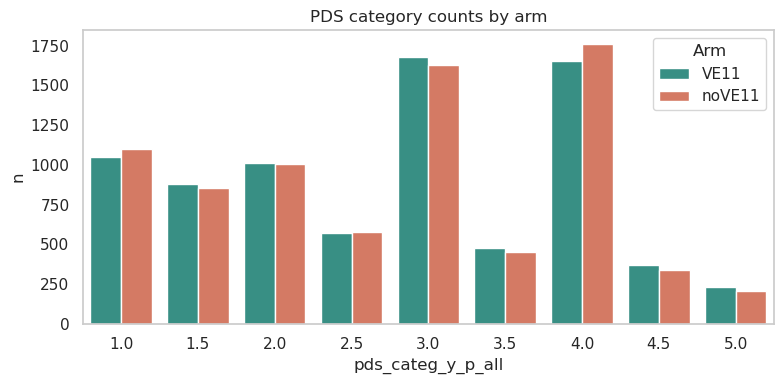

In [48]:
pds_col = "pds_categ_y_p_all"
if pds_col in df.columns:
    pds_counts = (
        df.groupby([STRATUM_COL, pds_col], observed=True)
        .size()
        .reset_index(name="n")
    )
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.barplot(
        data=pds_counts, x=pds_col, y="n", hue=STRATUM_COL,
        hue_order=STRATUM_ORDER, palette=STRATUM_PALETTE, ax=ax,
    )
    ax.set_title("PDS category counts by arm")
    ax.legend(title="Arm")
    ax.grid(False)
    fig.tight_layout()
    save_fig(fig, "matched_pds_counts_ve11_vs_nove11")
    plt.show()
else:
    print(f"{pds_col} not in datafile")


## Age vs perc_median


Saved /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/ve11_vs_noVE11_6_0/matching/qc/figures/matched_age_vs_perc_median_scatter.png


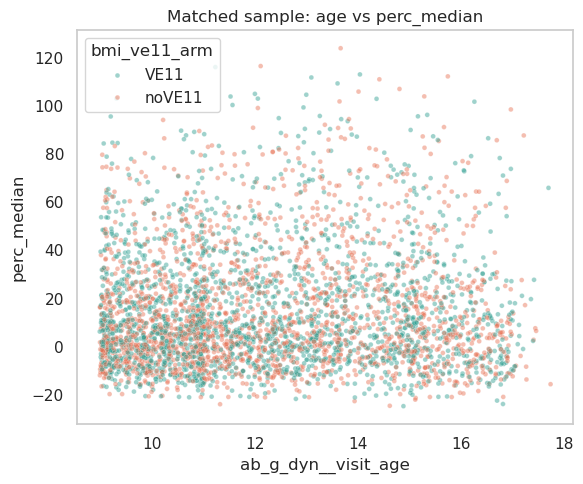

In [49]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.scatterplot(
    data=df.sample(n=min(4000, len(df)), random_state=0),
    x="ab_g_dyn__visit_age",
    y="perc_median",
    hue=STRATUM_COL,
    hue_order=STRATUM_ORDER,
    palette=STRATUM_PALETTE,
    s=12,
    alpha=0.45,
    ax=ax,
)
ax.set_title("Matched sample: age vs perc_median")
ax.grid(False)
fig.tight_layout()
save_fig(fig, "matched_age_vs_perc_median_scatter")
plt.show()


## Observations per visit (arm-stratified)

Same by-visit layout as `distribution_sample_bmi_voxelwise.ipynb`, but colored by **VE11 / noVE11** (no heatmaps).


bmi_ve11_arm,VE11,noVE11
session_label,,
Baseline,3002,2892
Year 2,2086,2127
Year 4,1759,1666
Year 6,1084,1246


Saved /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/ve11_vs_noVE11_6_0/matching/qc/figures/matched_observations_by_session_arm.png


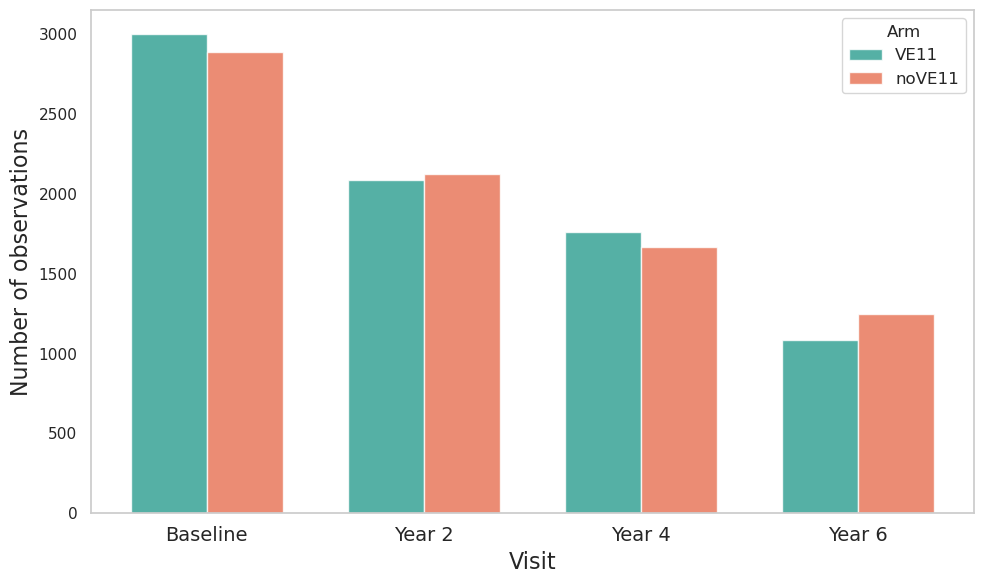

In [50]:
counts = (
    label_sessions(df)
    .groupby(["session_label", STRATUM_COL], dropna=False)
    .size()
    .unstack(fill_value=0)
    .reindex(columns=STRATUM_ORDER)
    .reindex(session_label_order(df))
)

display(counts)

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(counts.index))
width = 0.35
ax.bar(
    x, counts.get("VE11", 0), width,
    label=STRATUM_LABELS["VE11"], color=STRATUM_PALETTE["VE11"], alpha=0.8,
)
ax.bar(
    x + width, counts.get("noVE11", 0), width,
    label=STRATUM_LABELS["noVE11"], color=STRATUM_PALETTE["noVE11"], alpha=0.8,
)
ax.set_xticks(x + width / 2)
ax.set_xticklabels(counts.index, fontsize=14)
ax.set_xlabel("Visit", fontsize=16)
ax.set_ylabel("Number of observations", fontsize=16)
ax.legend(title="Arm", fontsize=12)
ax.grid(False)
plt.tight_layout()
save_fig(fig, "matched_observations_by_session_arm")
plt.show()


## Faceted histograms by visit

One panel per session; overlay **VE11** vs **noVE11**. Includes age, bmip, BMI, perc_median, and **PDS**.


In [ ]:
for key, spec in DIST_SPECS.items():
    col = spec["column"]
    if col not in df.columns:
        print(f"Skipping {col} (not in datafile)")
        continue

    plot_df = label_sessions(df.dropna(subset=[col, "session_id", STRATUM_COL]).copy())
    if spec["xlim"] is not None:
        lo, hi = spec["xlim"]
        plot_df = plot_df[(plot_df[col] >= lo) & (plot_df[col] <= hi)]
    if plot_df.empty:
        print(f"Skipping {col} (no rows after filters)")
        continue

    bins = make_bins(spec, plot_df[col].to_numpy())
    session_order = session_label_order(plot_df)

    # DISPLOT_HUE_ORDER puts noVE11 first so orange ends up in front (seaborn hue quirk)
    displot_kw = dict(
        data=plot_df,
        x=col,
        col="session_label",
        col_order=session_order,
        col_wrap=4,
        hue=STRATUM_COL,
        hue_order=DISPLOT_HUE_ORDER,
        palette=STRATUM_PALETTE,
        bins=bins,
        stat="count",
        common_bins=True,
        common_norm=False,
        multiple="layer",
        alpha=0.5,
        height=3.1,
        aspect=1.2,
    )
    if HIST_BAR_EDGE:
        displot_kw["edgecolor"] = HIST_BAR_EDGE_COLOR
        displot_kw["linewidth"] = HIST_BAR_EDGE_WIDTH
    g = sns.displot(**displot_kw)
    g.set_axis_labels(spec["label"], "Count")
    g.set_titles("{col_name}")
    if spec["xlim"] is not None:
        g.set(xlim=spec["xlim"])
    for ax in g.axes.flat:
        if ax is not None:
            ax.grid(False)
    g.fig.subplots_adjust(top=0.88)
    # Keep legend in VE11 / noVE11 order (same as overall plots)
    if g._legend is not None:
        g._legend.set_title("Arm")
        handles = g._legend.legend_handles
        texts = [t.get_text() for t in g._legend.texts]
        label_to_handle = dict(zip(texts, handles))
        ordered_labels = [STRATUM_LABELS[s] for s in STRATUM_ORDER if STRATUM_LABELS[s] in label_to_handle]
        if not ordered_labels:
            ordered_labels = [s for s in STRATUM_ORDER if s in label_to_handle]
        ordered_handles = [label_to_handle[lab] for lab in ordered_labels]
        g._legend.remove()
        g.fig.legend(
            ordered_handles, ordered_labels,
            title="Arm", loc="upper right", frameon=True,
        )
    save_fig(g.fig, f"matched_{spec['short']}_histogram_by_session")
    plt.show()
